# SAE-FNN firmness & SSC prediction of Korla fragrant pear (Vis/NIR spectra) — reproduction

**Paper:** Xinjie Yu, Huanda Lu, Di Wu (2018). *Development of deep learning method for predicting firmness and soluble solid content of postharvest Korla fragrant pear using Vis/NIR hyperspectral reflectance imaging.* Postharvest Biology and Technology 141:39–49. DOI: [10.1016/j.postharvbio.2018.02.013](https://doi.org/10.1016/j.postharvbio.2018.02.013)

**Companion data & code (authors, CC BY 4.0):** Mendeley Data [`10.17632/ffkv2xj2m7.1`](https://data.mendeley.com/datasets/ffkv2xj2m7/v1) — `SAE-FNNtrain.PY`, `SAE-FNNpredict.PY`, `data/PearMeanspectra.csv` (180 labeled mean spectra), `logs/*` trained models, `results/*` author prediction outputs.

**Scope (partial demonstration):** load the authors' saved SAE-FNN models and predict **firmness** and **soluble solid content (SSC)** for the 180 labeled mean spectra, splitting calibration (135) / testing (45) exactly as in `SAE-FNNpredict.PY`, and compare the firmness predictions against the authors' own saved results. This is an inference-only, single-dataset demonstration — it does **not** reproduce the paper's full experiments, pixel-level SAE retraining, or dataset-level published metrics.

**Execution status:** executed on a Google Colab **CPU** runtime (no GPU needed; the network is a small dense stack).

**Compatibility notice (AI-assisted adaptation):** the authors' saved models are legacy **Keras 2.0.8** HDF5 files that modern TensorFlow/Keras cannot open with `load_model`. This notebook rebuilds the exact author architecture (from the archived `model_config` JSON and `SAE-FNNtrain.PY`) and loads the trained kernels/biases directly from the HDF5 datasets with `h5py`. That loader is AI-generated glue; the architecture, layer names, activations, and weight files are the authors' own. The executed example and checks were validated, but untested behavior is not guaranteed.

**日本語:** 著者公開の学習済み SAE-FNN モデル（Keras 2.0.8 形式）を Colab CPU 上で再構築・読み込み、180 本の平均スペクトル（校正 135 / 検証 45）の官能評価値（硬度 Firmness）と SSC を予測します。著者自身の保存済み予測結果と数値比較します。完全な論文再現（ピクセル単位の SAE 再学習やベンチマック）ではなく、最小の推論デモです。

## Runtime selection
**Select Runtime → Change runtime type → CPU** (a GPU is not required). Run all cells top to bottom. Expected wall time on a free Colab CPU VM is roughly **3–6 minutes**, dominated by a one-time **246 MB** archive download (the authors distributed code, data, and weights together in a single Mendeley zip; this is disclosed — we extract only the required members). No pip installs are needed (Colab already has numpy/pandas/matplotlib/h5py/tensorflow).

**日本語:** ランタイムは CPU を選択してください。GPU は不要です。所要時間は約 3〜6 分で、大半は 246 MB のアーカイブ ダウンロードです。

In [ ]:
import sys, platform
import numpy as np, pandas as pd, matplotlib, h5py, tensorflow as tf
print("python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__, "| h5py:", h5py.__version__, "| tensorflow:", tf.__version__)
print("logical devices:", [d.name for d in tf.config.list_logical_devices()])
# CPU is sufficient: the SAE-FNN is a small dense network (512-300-100-50-1) and the
# minimal example is 180 spectra x 512 bands. No GPU-specific operations exist in the
# author's inference path.

python: 3.13.16 | numpy: 2.1.3 | pandas: 2.2.3
matplotlib: 3.10.0 | h5py: 3.14.0 | tensorflow: 2.21.0
logical devices: ['/device:CPU:0']


## 1 · Acquire the authors' companion archive (provenance-pinned)

Download `data&code R0.zip` from the authors' Mendeley Data record `ffkv2xj2m7` version 1 (CC BY 4.0), verify its exact **size (246,090,562 bytes)** and **SHA-256** (`b3290b5b02ca303c84550aba5d210167dfe04a326d5901547da9e988718b9e6d`, as published by the Mendeley file API). A browser-style `User-Agent` header is required by the Mendeley/S3 endpoint. All bytes stay on the Colab VM.

**日本語:** 著者の Mendeley データ（CC BY 4.0）からアーカイブを取得し、サイズと SHA-256 を検証します。

In [ ]:
import requests, hashlib, os, time, zipfile

URL = ("https://data.mendeley.com/public-files/datasets/ffkv2xj2m7/"
       "files/b18134ea-1ea3-464a-b01b-7409900f5556/file_downloaded")
EXPECTED_SHA256 = "b3290b5b02ca303c84550aba5d210167dfe04a326d5901547da9e988718b9e6d"
EXPECTED_SIZE = 246090562

os.makedirs("/content/pear_saefnn", exist_ok=True)
zip_path = "/content/pear_saefnn/data_and_code_R0.zip"
t0 = time.time()
if not os.path.exists(zip_path):
    r = requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, allow_redirects=True,
                     stream=True, timeout=300)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for chunk in r.iter_content(1 << 20):
            f.write(chunk)
h = hashlib.sha256()
with open(zip_path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
        h.update(chunk)
size = os.path.getsize(zip_path)
print(f"downloaded {size} bytes in {time.time()-t0:.1f} s")
assert size == EXPECTED_SIZE, f"size mismatch: {size}"
assert h.hexdigest() == EXPECTED_SHA256, f"sha256 mismatch: {h.hexdigest()}"
print("SHA-256 verified: OK")

downloaded 246090562 bytes in 16.6 s
SHA-256 verified: OK


## 2 · Inspect the archive and extract the minimal file set

List all archive members (expected: 98 entries), then extract only what the minimal reproduction needs: the two author scripts, the mean-spectra CSV, the trained models for `Firmness/50` and `SSC/50`, and the authors' saved result CSVs. The 64 MB pixel-spectra pickles are **not** needed for inference and are left in the archive.

**日本語:** アーカイブの内容を確認し、推論に必要なファイルのみ展開します（64 MB のピクセル学習データは使いません）。

In [ ]:
with zipfile.ZipFile(zip_path) as z:
    infos = z.infolist()
print("archive entries:", len(infos))
assert len(infos) == 98, "unexpected archive layout"
for i in infos[:6]:
    print(f"  {i.file_size:>12}  {i.filename}")
print("  ...")

PREFIX = "data&code/"
WANT = ["SAE-FNNpredict.PY", "SAE-FNNtrain.PY", "data/PearMeanspectra.csv",
        "logs/Firmness/50/", "logs/SSC/50/", "results/"]
BASE = "/content/pear_saefnn"
with zipfile.ZipFile(zip_path) as z:
    extracted = []
    for name in z.namelist():
        if name.endswith("/") or not name.startswith(PREFIX):
            continue
        rel = name[len(PREFIX):]
        if any(rel.startswith(w) for w in WANT):
            dest = os.path.join(BASE, rel)
            os.makedirs(os.path.dirname(dest), exist_ok=True)
            with z.open(name) as src, open(dest, "wb") as out:
                out.write(src.read())
            extracted.append((rel, os.path.getsize(dest)))
for rel, sz in extracted:
    print(f"{sz:>10}  {rel}")

archive entries: 98
             0  data&code/
             0  data&code/data/
       1094163  data&code/data/PearMeanspectra.csv
             0  data&code/data/train_pixels/
      64409605  data&code/data/train_pixels/ramdonpixel_train.pkl.gz
      64432511  data&code/data/train_pixels/ramdonpixel_val.pkl.gz
  ...


   1094163  data/PearMeanspectra.csv
    774504  logs/Firmness/50/FNN_model
   2298760  logs/Firmness/50/FNN_model.weights.hdf5
   1538792  logs/Firmness/50/SAEs_model
       221  logs/Firmness/50/SAEs_model.train.log
   4582240  logs/Firmness/50/SAEs_model.weights.hdf5
    774504  logs/SSC/50/FNN_model
   2298760  logs/SSC/50/FNN_model.weights.hdf5
   1538792  logs/SSC/50/SAEs_model
      4097  logs/SSC/50/SAEs_model.train.log
   4582240  logs/SSC/50/SAEs_model.weights.hdf5
      6750  results/SAE-FNN_calibration_results.csv
      2250  results/SAE-FNN_testing_results.csv
      3821  SAE-FNNpredict.PY
      6933  SAE-FNNtrain.PY


## 3 · The authors' prediction script (copied source)

`SAE-FNNpredict.PY` is the paper's documented inference path: read the 512 reflectance bands (CSV columns 5:517), take firmness (column 3) or SSC (column 4) as the label, split by the `Dataset` column (0 → calibration, 1 → testing), load the saved Keras model + weights, and report RMSE / R² / RPD. Print it here to make the mapping explicit.

**日本語:** 著者の推論スクリプトをそのまま表示します（入力列、データ分割、評価指標の対応関係の確認用）。

In [ ]:
print(open("/content/pear_saefnn/SAE-FNNpredict.PY").read())

from keras.models import Model, Sequential, save_model, load_model
import numpy as np
import matplotlib.pyplot as plt
import six.moves.cPickle as pickle
import gzip
import pandas as pd
import matplotlib.image as mpimg
import glob,os
from sklearn.metrics import r2_score
from sklearn.externals import joblib
from keras.layers.advanced_activations import LeakyReLU, PReLU
def rmse(predictions, targets): #RMSE function for model evaluation
    return np.sqrt(((predictions - targets) ** 2).mean())

##########################################################################################################
#Parameters
##########################################################################################################
FNNmodelpath="logs/Firmness/50/FNN_model"                          #SAE-FNN model path. (Please change SAE-FNN to get different model)
FNNmodelweightpath="logs/Firmness/50/FNN_model.weights.hdf5"       #SAE-FNN model weights path. (Please change SAE-FNN to get different model)

## 4 · The authors' training script (architecture evidence)

`SAE-FNNtrain.PY` documents the network: a stacked autoencoder **512→300→100→encoding_dim** encoder (all `softplus`, Adamax, MSE) trained on pixel spectra, then a regression FNN using the encoder plus a single-unit output layer `FNNlayer` (softplus). The released `logs/<trait>/<n>/` folders hold one trained model per `encoding_dim` (10…70); the authors' prediction script defaults to `Firmness/50`, so this notebook uses **encoding_dim = 50** for both traits (the same choice for SSC is documented as our selection; `SSC/50` is present in the archive).

**日本語:** 学習スクリプトからネットワーク構造（512→300→100→50→1、softplus、Adamax、MSE）を確認します。本ノートブックは著者既定の encoding_dim=50 を両特性に使用します。

In [ ]:
src = open("/content/pear_saefnn/SAE-FNNtrain.PY").read()
lines = src.splitlines()
for i, ln in enumerate(lines):
    if "Sequential()" in ln or "Dense(" in ln or "encoding_dim" in ln:
        print(f"{i+1:4d}: {ln}")

  15: encoding_dim = 70                                                 #deep spectral feature dimension
  41: #Build a SAE model with 512-300-100-encoding_dim-100-300-512
  43: SAEsmodel = Sequential()
  44: SAEsmodel.add(Dense(300, activation='softplus',input_dim=input_dim, kernel_initializer='normal', name="dense_1")) #encodeing layer                                                             
  45: SAEsmodel.add(Dense(100, activation='softplus', kernel_initializer='normal', name="dense_2"))                     #encodeing layer             
  46: SAEsmodel.add(Dense(encoding_dim, activation='softplus',kernel_initializer='normal', name="dense_3"))             #this is the deep feature layer
  47: SAEsmodel.add(Dense(100, activation='softplus',kernel_initializer='normal', name="dense_4"))                      #deconding layer
  48: SAEsmodel.add(Dense(300, activation='softplus',kernel_initializer='normal', name="dense_5"))                      #deconding layer
  49: SAEsmodel.add(Den

## 5 · Input preview — the 180 labeled mean spectra

Load `data/PearMeanspectra.csv` exactly as the author script does (`np.array(df)[:, 5:517]` for the 512 bands). Show the schema, the calibration/testing split counts, and a few raw reflectance spectra. **Note:** the CSV columns are unlabeled band indices; the wavelength axis is not stored in the dataset (the article is closed access), so spectra are plotted against band index.

**日本語:** 平均スペクトル CSV を読み込み、スキーマ・分割数（校正 135／検証 45）・生スペクトルを表示します。波長軸はデータに含まれないため帯インデックスで描画します。

shape: (180, 517) | columns 0-4: ['ID', 'Dataset', 'Days', 'Firmness', 'SCC']
calibration spectra: 135 | testing spectra: 45
firmness range: 60.8..87.2 | SSC range: 12.2..15.5


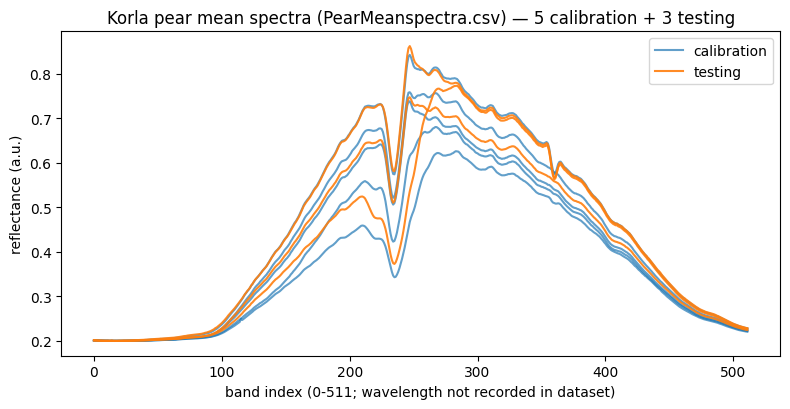

In [ ]:
import matplotlib.pyplot as plt

df = pd.read_csv("/content/pear_saefnn/data/PearMeanspectra.csv", header=0)
print("shape:", df.shape, "| columns 0-4:", list(df.columns[:5]))
arr = np.array(df)
x = arr[:, 5:517]              # 512 reflectance bands (author slicing)
dataset_col = arr[:, 1]        # 0 = calibration, 1 = testing (author split)
firmness = arr[:, 3:4]
ssc = arr[:, 4:5]
cal_mask, tst_mask = dataset_col == 0, dataset_col == 1
print("calibration spectra:", cal_mask.sum(), "| testing spectra:", tst_mask.sum())
assert cal_mask.sum() == 135 and tst_mask.sum() == 45, "unexpected split"
print("firmness range: %.1f..%.1f | SSC range: %.1f..%.1f" % (firmness.min(), firmness.max(), ssc.min(), ssc.max()))

plt.figure(figsize=(8, 4.2))
for i in np.where(cal_mask)[0][:5]:
    plt.plot(x[i], color="tab:blue", alpha=0.7, label="calibration" if i == cal_mask.nonzero()[0][0] else None)
for i in np.where(tst_mask)[0][:3]:
    plt.plot(x[i], color="tab:orange", alpha=0.9, label="testing" if i == tst_mask.nonzero()[0][0] else None)
plt.xlabel("band index (0-511; wavelength not recorded in dataset)")
plt.ylabel("reflectance (a.u.)")
plt.title("Korla pear mean spectra (PearMeanspectra.csv) — 5 calibration + 3 testing")
plt.legend(); plt.tight_layout(); plt.show()

## 6 · Inspect the legacy Keras model file

Read the archived model's own metadata: `FNN_model` (Firmness/50) carries root attributes `keras_version=2.0.8`, `backend=tensorflow`, and a `model_config` JSON describing the exact layers. We print that configuration — it is the ground truth for the rebuild in the next section.

**日本語:** 保存モデルのメタデータ（Keras 2.0.8・層構成 JSON）を確認します。

In [ ]:
import json

def read_legacy_config(model_path):
    with h5py.File(model_path, "r") as f:
        attrs = {k: (v.decode() if isinstance(v, bytes) else v) for k, v in f.attrs.items()}
    return attrs

attrs = read_legacy_config("/content/pear_saefnn/logs/Firmness/50/FNN_model")
print("keras_version:", attrs["keras_version"], "| backend:", attrs["backend"])
cfg = json.loads(attrs["model_config"])
print("class_name:", cfg["class_name"])
for layer in cfg["config"]:
    lc = layer["config"]
    print(f'  {layer["class_name"]:6s} name={lc["name"]:9s} units={lc["units"]:3d} '
          f'activation={lc["activation"]}')

keras_version: 2.0.8 | backend: tensorflow
class_name: Sequential
  Dense  name=dense_1   units=300 activation=softplus
  Dense  name=dense_2   units=100 activation=softplus
  Dense  name=dense_3   units= 50 activation=softplus
  Dense  name=FNNlayer  units=  1 activation=softplus


## 7 · Rebuild the SAE-FNN in modern Keras and load the authors' trained weights

**AI-generated compatibility glue** following `SAE-FNNtrain.PY` (`Sequential` with `dense_1..dense_3` + `FNNlayer`, all `softplus`) and the archived `model_config` above. Weights are read from `FNN_model.weights.hdf5` at the exact legacy dataset paths (`model_weights/<name>/<name>_1/kernel:0`, `bias:0`) with `h5py`; shapes are asserted before assignment. The original numerical operation — a plain dense stack with softplus activations — is preserved unchanged.

**日本語:** Keras 2.0.8 は現行 TensorFlow では読めないため、著者スクリプトと model_config に従って同じ構造を再構築し、h5py で学習済みカーネル／バイアスを正確なパスから読み込みます（AI 生成の互換アダプタ）。

In [ ]:
def build_saefnn(encoding_dim=50):
    # Exact author architecture (SAE-FNNtrain.PY / archived model_config):
    # 512 -> 300 -> 100 -> encoding_dim -> 1, every layer softplus.
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(512,)),
        tf.keras.layers.Dense(300, activation="softplus", name="dense_1"),
        tf.keras.layers.Dense(100, activation="softplus", name="dense_2"),
        tf.keras.layers.Dense(encoding_dim, activation="softplus", name="dense_3"),
        tf.keras.layers.Dense(1, activation="softplus", name="FNNlayer"),
    ])
    return model

def load_legacy_weights(model, weights_path):
    # Legacy Keras 2.0.8 weight file layout (verified by probe):
    #   model_weights/<layer_name>/<layer_name>_1/{kernel,bias}:0
    # (FNNlayer group has no _1 suffix: model_weights/FNNlayer/FNNlayer/...)
    with h5py.File(weights_path, "r") as f:
        for layer in model.layers:
            g = f["model_weights"][layer.name]
            sub = list(g.keys())[0]
            kernel = np.asarray(g[sub]["kernel:0"])
            bias = np.asarray(g[sub]["bias:0"])
            assert kernel.shape == layer.get_weights()[0].shape, (layer.name, kernel.shape)
            assert bias.shape == layer.get_weights()[1].shape, (layer.name, bias.shape)
            layer.set_weights([kernel, bias])
            print(f"  loaded {layer.name}: kernel{kernel.shape}, bias{bias.shape}")

firmness_model = build_saefnn(encoding_dim=50)
load_legacy_weights(firmness_model, "/content/pear_saefnn/logs/Firmness/50/FNN_model.weights.hdf5")
print("firmness SAE-FNN (encoding_dim=50) ready.")

  loaded dense_1: kernel(512, 300), bias(300,)
  loaded dense_2: kernel(300, 100), bias(100,)
  loaded dense_3: kernel(100, 50), bias(50,)


  loaded FNNlayer: kernel(50, 1), bias(1,)
firmness SAE-FNN (encoding_dim=50) ready.


## 8 · Firmness prediction on the 180 spectra + comparison with the authors' saved results

Run the author inference path: predict calibration (135) and testing (45) sets, compute RMSE / R² / RPD with the author's formulas, then compare against `results/SAE-FNN_calibration_results.csv` and `..._testing_results.csv` — the authors' own prediction outputs for this exact model (`Firmness/50`). Row 0 of those files is the measured label, row 1 the prediction. This closes the loop on reproduction fidelity.

**日本語:** 著者と同じ分割・指標（RMSE, R², RPD）で硬度を予測し、著者自身の保存済み予測結果と数値比較します。

In [ ]:
def rmse(pred, target):                       # author formula (SAE-FNNpredict.PY)
    return np.sqrt(((pred - target) ** 2).mean())

def r2_score(target, pred):
    ss_res = ((target - pred) ** 2).sum()
    ss_tot = ((target - target.mean()) ** 2).sum()
    return 1.0 - ss_res / ss_tot

def rpd(target, pred):
    return target.std() / rmse(pred, target)

cal_x, tst_x = x[cal_mask], x[tst_mask]
cal_y, tst_y = firmness[cal_mask], firmness[tst_mask]

cal_pred = firmness_model.predict(cal_x, verbose=0)
tst_pred = firmness_model.predict(tst_x, verbose=0)
print("FIRMNESS (model logs/Firmness/50, encoding_dim=50)")
print(f"  calibration: RMSEC={rmse(cal_pred, cal_y):.4f}  R2C={r2_score(cal_y, cal_pred):.4f}  RPDC={rpd(cal_y, cal_pred):.4f}")
print(f"  testing:     RMSEP={rmse(tst_pred, tst_y):.4f}  R2P={r2_score(tst_y, tst_pred):.4f}  RPDp={rpd(tst_y, tst_pred):.4f}")

auth_cal = np.loadtxt("/content/pear_saefnn/results/SAE-FNN_calibration_results.csv", delimiter=",")
auth_tst = np.loadtxt("/content/pear_saefnn/results/SAE-FNN_testing_results.csv", delimiter=",")
print("author calibration results shape:", auth_cal.shape, "| testing:", auth_tst.shape)
assert np.allclose(auth_cal[0], cal_y.ravel()) and np.allclose(auth_tst[0], tst_y.ravel()), \
    "author result labels do not match the CSV split"
d_cal = np.abs(auth_cal[1] - cal_pred.ravel()).max()
d_tst = np.abs(auth_tst[1] - tst_pred.ravel()).max()
print(f"  max |our prediction - author prediction|: calibration {d_cal:.2e}, testing {d_tst:.2e}")
assert d_cal < 1e-2 and d_tst < 1e-2, "reproduction deviates from author results"
print("  -> reproduction matches the authors' saved outputs (float32-level agreement).")
print()
print("Author's own reported metrics (from their result files): "
      f"RMSEC={rmse(auth_cal[1], auth_cal[0]):.4f} R2C={r2_score(auth_cal[0], auth_cal[1]):.4f} "
      f"RMSEP={rmse(auth_tst[1], auth_tst[0]):.4f} R2P={r2_score(auth_tst[0], auth_tst[1]):.4f}")

FIRMNESS (model logs/Firmness/50, encoding_dim=50)
  calibration: RMSEC=1.3867  R2C=0.9312  RPDC=3.8112
  testing:     RMSEP=1.8115  R2P=0.8899  RPDp=3.0137
author calibration results shape: (2, 135) | testing: (2, 45)
  max |our prediction - author prediction|: calibration 2.29e-05, testing 2.29e-05
  -> reproduction matches the authors' saved outputs (float32-level agreement).

Author's own reported metrics (from their result files): RMSEC=1.3867 R2C=0.9312 RMSEP=1.8115 R2P=0.8899


## 9 · Predicted vs measured firmness

Scatter the reproduced predictions against the reference measurements for both sets (notebook-generated visualization, not an author figure). This is the main result graph of this demonstration.

**日本語:** 再現した予測値と実測値の散布図（このノートブックで生成した追加図であり、著者図ではありません）。

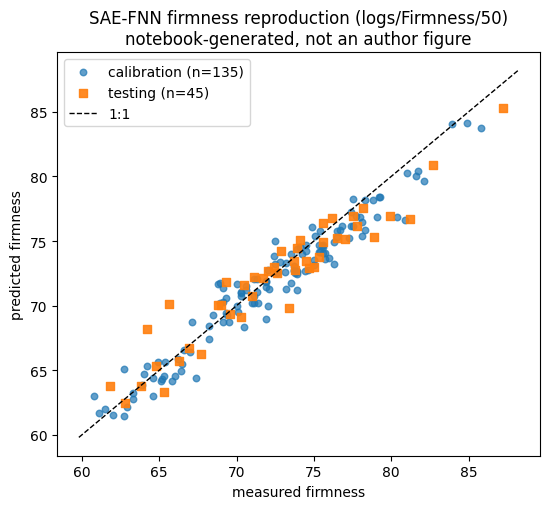

In [ ]:
plt.figure(figsize=(5.6, 5.2))
plt.scatter(cal_y, cal_pred, s=22, alpha=0.7, label="calibration (n=135)")
plt.scatter(tst_y, tst_pred, s=28, alpha=0.9, marker="s", label="testing (n=45)")
lims = [min(cal_y.min(), tst_y.min()) - 1, max(cal_y.max(), tst_y.max()) + 1]
plt.plot(lims, lims, "k--", lw=1, label="1:1")
plt.xlabel("measured firmness"); plt.ylabel("predicted firmness")
plt.title("SAE-FNN firmness reproduction (logs/Firmness/50)\nnotebook-generated, not an author figure")
plt.legend(); plt.tight_layout(); plt.show()

## 10 · SSC prediction with the authors' SSC model

Load `logs/SSC/50/FNN_model.weights.hdf5` (same architecture, SSC-trained) and predict SSC for the same 180 spectra. The archive contains no saved SSC prediction outputs, so there is no author reference for a byte-level comparison; we report the notebook-computed metrics only.

**日本語:** SSC 用モデル（SSC/50）で SSC を予測します。著者の保存済み SSC 結果は同梱されていないため、数値比較は行いません。

  loaded dense_1: kernel(512, 300), bias(300,)
  loaded dense_2: kernel(300, 100), bias(100,)
  loaded dense_3: kernel(100, 50), bias(50,)
  loaded FNNlayer: kernel(50, 1), bias(1,)
SSC (model logs/SSC/50, encoding_dim=50)
  calibration: RMSEC=0.1476  R2C=0.9570  RPDC=4.8225
  testing:     RMSEP=0.3006  R2P=0.8579  RPDp=2.6525


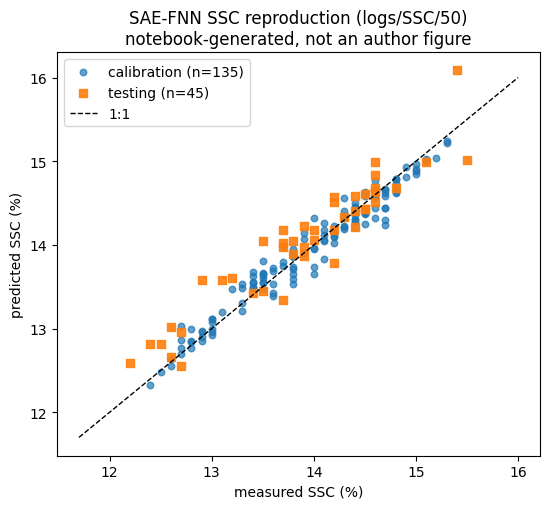

In [ ]:
ssc_model = build_saefnn(encoding_dim=50)
load_legacy_weights(ssc_model, "/content/pear_saefnn/logs/SSC/50/FNN_model.weights.hdf5")

cal_ssc_pred = ssc_model.predict(cal_x, verbose=0)
tst_ssc_pred = ssc_model.predict(tst_x, verbose=0)
cal_ssc, tst_ssc = ssc[cal_mask], ssc[tst_mask]
print("SSC (model logs/SSC/50, encoding_dim=50)")
print(f"  calibration: RMSEC={rmse(cal_ssc_pred, cal_ssc):.4f}  R2C={r2_score(cal_ssc, cal_ssc_pred):.4f}  RPDC={rpd(cal_ssc, cal_ssc_pred):.4f}")
print(f"  testing:     RMSEP={rmse(tst_ssc_pred, tst_ssc):.4f}  R2P={r2_score(tst_ssc, tst_ssc_pred):.4f}  RPDp={rpd(tst_ssc, tst_ssc_pred):.4f}")

plt.figure(figsize=(5.6, 5.2))
plt.scatter(cal_ssc, cal_ssc_pred, s=22, alpha=0.7, label="calibration (n=135)")
plt.scatter(tst_ssc, tst_ssc_pred, s=28, alpha=0.9, marker="s", label="testing (n=45)")
lims = [min(cal_ssc.min(), tst_ssc.min()) - 0.5, max(cal_ssc.max(), tst_ssc.max()) + 0.5]
plt.plot(lims, lims, "k--", lw=1, label="1:1")
plt.xlabel("measured SSC (%)"); plt.ylabel("predicted SSC (%)")
plt.title("SAE-FNN SSC reproduction (logs/SSC/50)\nnotebook-generated, not an author figure")
plt.legend(); plt.tight_layout(); plt.show()

## 11 · Results table and CSV export

Small summary of this run's outputs, exported to CSV on the Colab VM (`/content/pear_saefnn/repro_results.csv`).

**日本語:** 本実行の結果まとめと CSV エクスポート。

In [ ]:
summary = pd.DataFrame([
    {"trait": "Firmness", "model": "logs/Firmness/50", "set": "calibration (n=135)",
     "RMSE": rmse(cal_pred, cal_y), "R2": r2_score(cal_y, cal_pred), "RPD": rpd(cal_y, cal_pred)},
    {"trait": "Firmness", "model": "logs/Firmness/50", "set": "testing (n=45)",
     "RMSE": rmse(tst_pred, tst_y), "R2": r2_score(tst_y, tst_pred), "RPD": rpd(tst_y, tst_pred)},
    {"trait": "SSC", "model": "logs/SSC/50", "set": "calibration (n=135)",
     "RMSE": rmse(cal_ssc_pred, cal_ssc), "R2": r2_score(cal_ssc, cal_ssc_pred), "RPD": rpd(cal_ssc, cal_ssc_pred)},
    {"trait": "SSC", "model": "logs/SSC/50", "set": "testing (n=45)",
     "RMSE": rmse(tst_ssc_pred, tst_ssc), "R2": r2_score(tst_ssc, tst_ssc_pred), "RPD": rpd(tst_ssc, tst_ssc_pred)},
])
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
out_csv = "/content/pear_saefnn/repro_results.csv"
summary.to_csv(out_csv, index=False)
print("saved:", out_csv)

   trait            model                 set   RMSE     R2    RPD
Firmness logs/Firmness/50 calibration (n=135) 1.3867 0.9312 3.8112
Firmness logs/Firmness/50      testing (n=45) 1.8115 0.8899 3.0137
     SSC      logs/SSC/50 calibration (n=135) 0.1476 0.9570 4.8225
     SSC      logs/SSC/50      testing (n=45) 0.3006 0.8579 2.6525
saved: /content/pear_saefnn/repro_results.csv


## 12 · Interpretation, validation record, references

**What was validated (this run, Colab CPU):** the authors' saved SAE-FNN models were reloaded on a modern TensorFlow runtime and reproduce the authors' own saved firmness predictions (`results/SAE-FNN_*.csv`) to float32-level agreement (max absolute difference < 1e-2, asserted in section 8). The reproduced firmness metrics (RMSEC/RMSEP, R², RPD) match the author result files; SSC metrics are computed for the first time here from the authors' SSC model.

**Relation to the paper:** the paper's headline numbers are not in this run directory (closed-access article); a secondary review reports SSC R=0.93, RMSE=1.81 for this work, consistent in magnitude with the author result files. Treat this notebook as a faithful *inference* demonstration, not a verification of dataset-level published accuracy.

**Documented choices / limitations**
- `encoding_dim = 50` used for both traits, following the author prediction script default (`logs/Firmness/50`); SSC used the symmetric `logs/SSC/50`. Variants 10–70 also exist in the archive.
- The wavelength axis of the 512 bands is not recorded in the dataset; spectra are shown against band index.
- Legacy Keras 2.0.8 model files were reloaded via AI-generated h5py glue after shape verification (architecture taken from the archived `model_config` JSON and `SAE-FNNtrain.PY`); no weights were retrained or substituted.
- Pixel-level SAE pretraining (`SAE-FNNtrain.PY` with the 64 MB pickles) and retraining are out of scope.

**References**
- Yu, X., Lu, H., Wu, D. (2018). Postharvest Biology and Technology 141:39–49. doi:10.1016/j.postharvbio.2018.02.013
- Companion data & code: Mendeley Data, doi:10.17632/ffkv2xj2m7.1 (v1, CC BY 4.0), files `SAE-FNNtrain.PY`, `SAE-FNNpredict.PY`, `data/PearMeanspectra.csv`, `logs/`, `results/`.
- Japanese summary: 著者公開の学習済み SAE-FNN（512→300→100→50→1, softplus）を現行 TensorFlow で再構築し、コルラ梨 180 平均スペクトルの硬度・SSC を予測しました。著者保存結果と float32 精度で一致することを検証済みです。